In [1]:
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from shared.paths import load_paths
paths = load_paths()



In [2]:
ROOT = Path(paths.cp4_2d) / "CP4_box_JASMIN/mean3h_v2/timeseries"

files = sorted(
    glob.glob(
        str(ROOT / "all_wetting_drydown_events_*_detailed_diagnostics.csv")
    )
)

event_file = files[-1]

print(Path(event_file).name)

ev = pd.read_csv(event_file)

# Only intervals for which a subsequent event exists.
ev = ev[
    np.isfinite(ev["available_drying_days"]) &
    np.isfinite(ev["dSM_to_min"]) &
    (ev["available_drying_days"] > 0)
].copy()

DEFS = ["SM>=2.5", "Rain>=5mm"]

display(
    ev.groupby(["definition", "label"])
      [["available_drying_days", "dSM_to_min"]]
      .median()
)

all_wetting_drydown_events_Aug08_hours171819_SMwet2p5_Rain5p0mm_Dry2p5_gap12h_pm30d_box23px_detailed_diagnostics.csv


available_drying_days  dSM_to_min
definition label                                    
Rain>=5mm  future               2.708333    7.495101
           hist                 2.166667    5.977790
SM>=2.5    future               3.000000    7.854619
           hist                 2.500000    6.297100

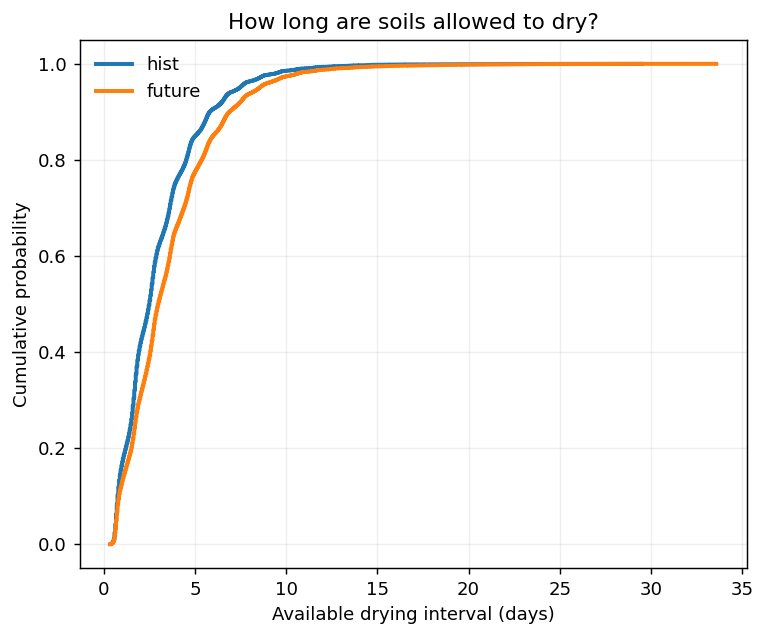

In [3]:
def ecdf(x):
    x = np.sort(np.asarray(x))
    x = x[np.isfinite(x)]
    return x, np.arange(1, len(x)+1) / len(x)


definition = "SM>=2.5"

fig, ax = plt.subplots(figsize=(6, 5), dpi=130)

for label in ["hist", "future"]:
    vals = ev[
        (ev["definition"] == definition) &
        (ev["label"] == label)
    ]["available_drying_days"]

    x, y = ecdf(vals)
    ax.plot(x, y, lw=2.2, label=label)

ax.set_xlabel("Available drying interval (days)")
ax.set_ylabel("Cumulative probability")
ax.set_title("How long are soils allowed to dry?")
ax.grid(alpha=0.2)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

hist 120 n = 21974 mean = 1.9426980384088173 median = 1.901237166740274
hist 240 n = 2107 mean = 1.1296358583452193 median = 1.072207043060635
future 120 n = 20261 mean = 2.4640696791049423 median = 2.467859714209849
future 240 n = 2358 mean = 1.3565439062980296 median = 1.3228668594165351


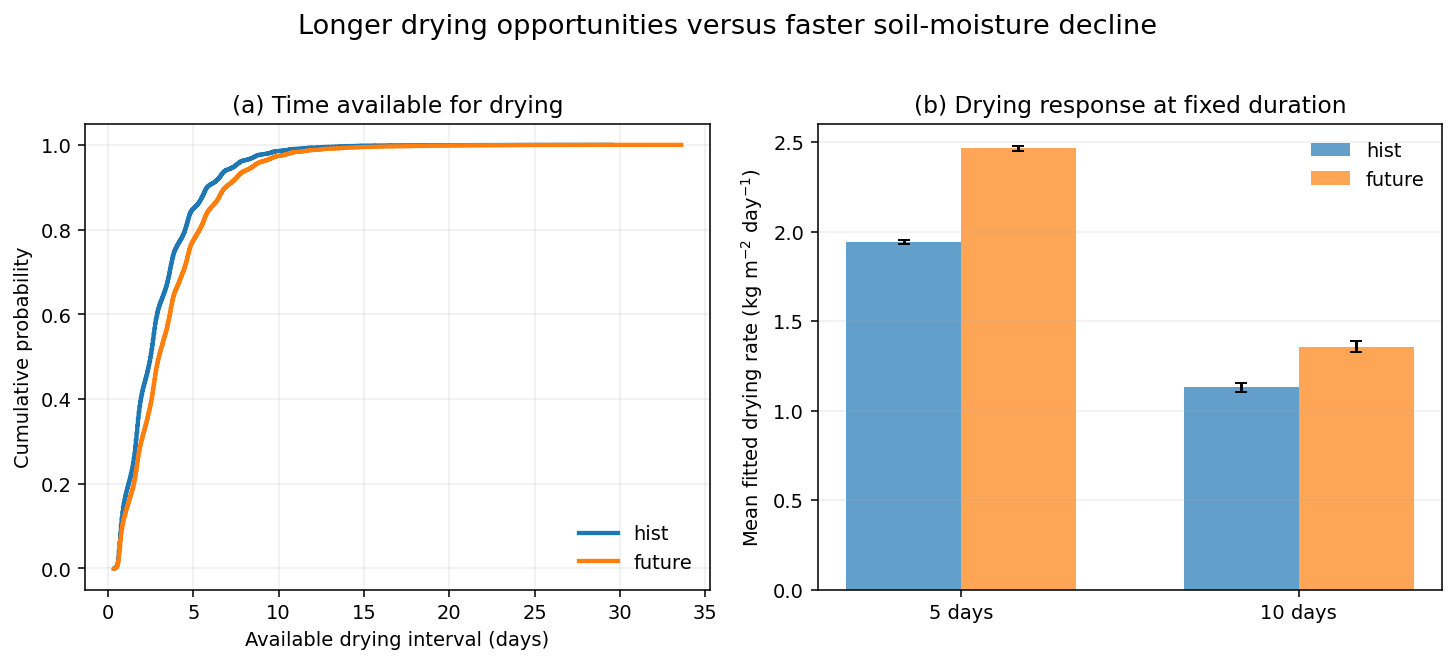

In [4]:
definition = "SM>=2.5"

fig, axes = plt.subplots(
    1, 2,
    figsize=(10.5, 4.6),
    dpi=140
)

# ============================================================
# (a) Available drying interval
# ============================================================

ax = axes[0]

for label in ["hist", "future"]:
    vals = ev[
        (ev["definition"] == definition) &
        (ev["label"] == label)
    ]["available_drying_days"]

    x, y = ecdf(vals)
    ax.plot(x, y, lw=2.2, label=label)

ax.set_xlabel("Available drying interval (days)")
ax.set_ylabel("Cumulative probability")
ax.set_title("(a) Time available for drying")
ax.grid(alpha=0.2)
ax.legend(frameon=False)


# ============================================================
# (b) Fixed-duration drying slope
# ============================================================

ax = axes[1]

horizons = [120, 240]
positions = np.arange(len(horizons))
width = 0.34

for j, label in enumerate(["hist", "future"]):

    means = []
    sems = []

    for h in horizons:

        vals = ev.loc[
            (ev["definition"] == definition) &
            (ev["label"] == label) &
            (ev[f"valid_{h}h"]),
            f"drying_slope_{h}h"
        ].dropna()

        means.append(vals.mean())
        sems.append(vals.std() / np.sqrt(len(vals)))

        print(
            label,
            h,
            "n =", len(vals),
            "mean =", vals.mean(),
            "median =", vals.median()
        )

    ax.bar(
        positions + (j-0.5)*width,
        means,
        width=width,
        yerr=np.array(sems) * 1.96,
        capsize=3,
        alpha=0.7,
        label=label,
    )

ax.set_xticks(positions)
ax.set_xticklabels(["5 days", "10 days"])
ax.set_ylabel(
    r"Mean fitted drying rate (kg m$^{-2}$ day$^{-1}$)"
)
ax.set_title("(b) Drying response at fixed duration")
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)

fig.suptitle(
    "Longer drying opportunities versus faster soil-moisture decline",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

In [5]:
for h in [48, 120, 240]:
    print(f"\n===== {h/24:g} days =====")

    print(
        ev[
            ev[f"valid_{h}h"]
        ]
        .groupby(["definition", "label"])[
            [f"dSM_{h}h", f"max_dSM_{h}h", f"drying_slope_{h}h"]
        ]
        .agg(["mean", "median", "count"])
        .round(2)
    )


===== 2 days =====
                  dSM_48h               max_dSM_48h                \
                     mean median  count        mean median  count   
definition label                                                    
Rain>=5mm  future    7.09   6.79  60161        7.27   6.89  60161   
           hist      5.92   5.74  78184        6.23   5.95  78184   
SM>=2.5    future    6.90   6.63  62336        7.11   6.75  62336   
           hist      5.77   5.61  85099        6.11   5.85  85099   

                  drying_slope_48h                
                              mean median  count  
definition label                                  
Rain>=5mm  future             3.36   3.36  60161  
           hist               2.81   2.83  78184  
SM>=2.5    future             3.30   3.31  62336  
           hist               2.76   2.77  85099  

===== 5 days =====
                  dSM_120h               max_dSM_120h                \
                      mean median  count        

In [6]:
definition = "SM>=2.5"

dd = ev[ev["definition"] == definition].copy()

bins = np.arange(0.5, 15.5, 0.5)

dd["duration_bin"] = pd.cut(
    dd["available_drying_days"],
    bins=bins
)

curve = (
    dd.groupby(
        ["label", "duration_bin"],
        observed=True
    )
    .agg(
        days=("available_drying_days", "median"),
        drying=("dSM_to_min", "mean"),
        n=("dSM_to_min", "size"),
    )
    .reset_index()
)

curve = curve[curve["n"] >= 50]

In [7]:
def drying_at_duration(curve, label, days):
    s = (
        curve[curve["label"] == label]
        .sort_values("days")
    )

    x = s["days"].values
    y = s["drying"].values

    if days < x.min() or days > x.max():
        return np.nan

    return np.interp(days, x, y)

In [8]:
percentiles = [25, 50, 75, 90]

rows = []

for p in percentiles:

    TH = np.percentile(
        dd.loc[
            dd["label"] == "hist",
            "available_drying_days"
        ],
        p
    )

    TF = np.percentile(
        dd.loc[
            dd["label"] == "future",
            "available_drying_days"
        ],
        p
    )

    # Four corners of duration x climate.
    HH = drying_at_duration(curve, "hist", TH)
    HF = drying_at_duration(curve, "hist", TF)

    FH = drying_at_duration(curve, "future", TH)
    FF = drying_at_duration(curve, "future", TF)

    total = FF - HH

    # Historical-reference pathway.
    duration_H = HF - HH
    response_H = FF - HF

    # Future-reference pathway.
    duration_F = FF - FH
    response_F = FH - HH

    # Symmetric / Shapley-style average.
    duration = 0.5 * (duration_H + duration_F)
    response = 0.5 * (response_H + response_F)

    rows.append({
        "percentile": p,

        "T_hist": TH,
        "T_future": TF,

        "D_hist_at_Thist": HH,
        "D_hist_at_Tfuture": HF,
        "D_future_at_Thist": FH,
        "D_future_at_Tfuture": FF,

        "total_difference": total,

        "duration_contribution": duration,
        "response_contribution": response,

        "duration_percent":
            100 * duration / total if total != 0 else np.nan,

        "response_percent":
            100 * response / total if total != 0 else np.nan,
    })

decomp = pd.DataFrame(rows)

display(decomp.round(2))

,percentile,T_hist,T_future,D_hist_at_Thist,D_hist_at_Tfuture,D_future_at_Thist,D_future_at_Tfuture,total_difference,duration_contribution,response_contribution,duration_percent,response_percent
0,25,1.50,1.71,4.90,5.31,4.85,5.32,0.41,0.44,-0.02,105.35,-5.35
1,50,2.50,3.00,7.06,7.98,7.93,9.19,2.13,1.09,1.04,51.18,48.82
2,75,3.92,4.75,9.36,10.35,10.70,12.48,3.12,1.39,1.73,44.45,55.55
3,90,5.79,6.88,11.53,12.88,13.67,15.92,4.39,1.80,2.59,41.01,58.99


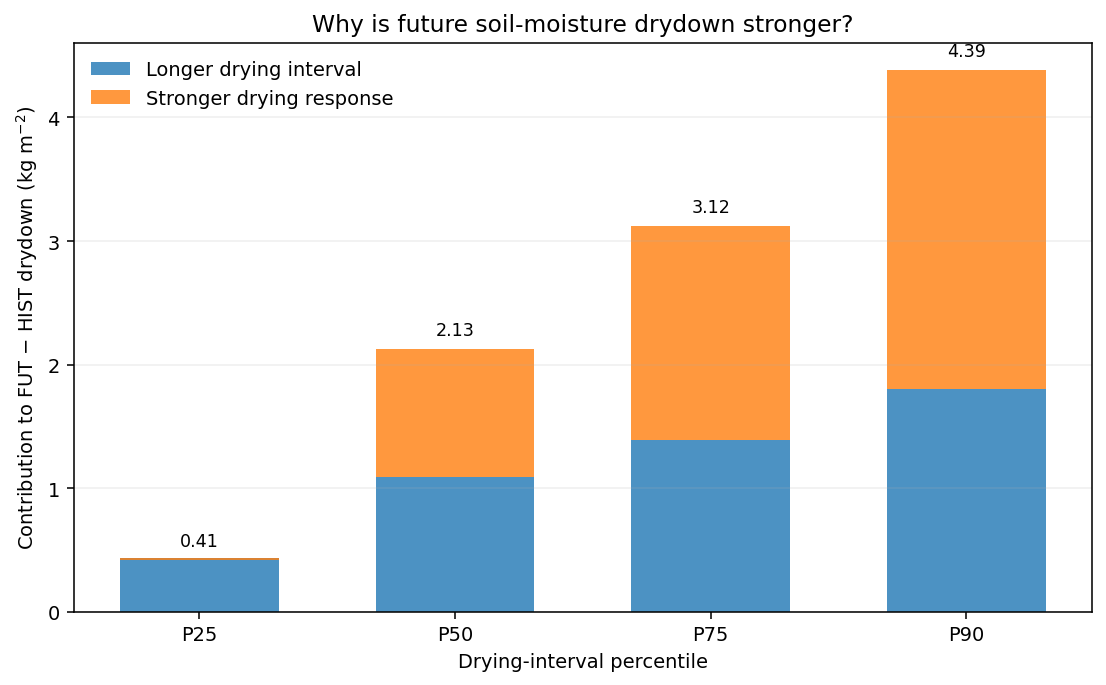

In [9]:
# ------------------------------------------------------------
# Absolute contribution to future-minus-historical drydown
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5), dpi=140)

x = np.arange(len(decomp))
dur = decomp["duration_contribution"].values
resp = decomp["response_contribution"].values
tot = decomp["total_difference"].values

ax.bar(
    x, dur,
    width=0.62,
    label="Longer drying interval",
    alpha=0.8
)

ax.bar(
    x, resp,
    width=0.62,
    bottom=dur,
    label="Stronger drying response",
    alpha=0.8
)

# total difference above bars
for i, total in enumerate(tot):
    ax.text(
        i,
        total + 0.08,
        f"{total:.2f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

ax.set_xticks(x)
ax.set_xticklabels(
    [f"P{int(p)}" for p in decomp["percentile"]]
)

ax.set_ylabel(
    r"Contribution to FUT − HIST drydown (kg m$^{-2}$)"
)

ax.set_xlabel("Drying-interval percentile")

ax.set_title(
    "Why is future soil-moisture drydown stronger?"
)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

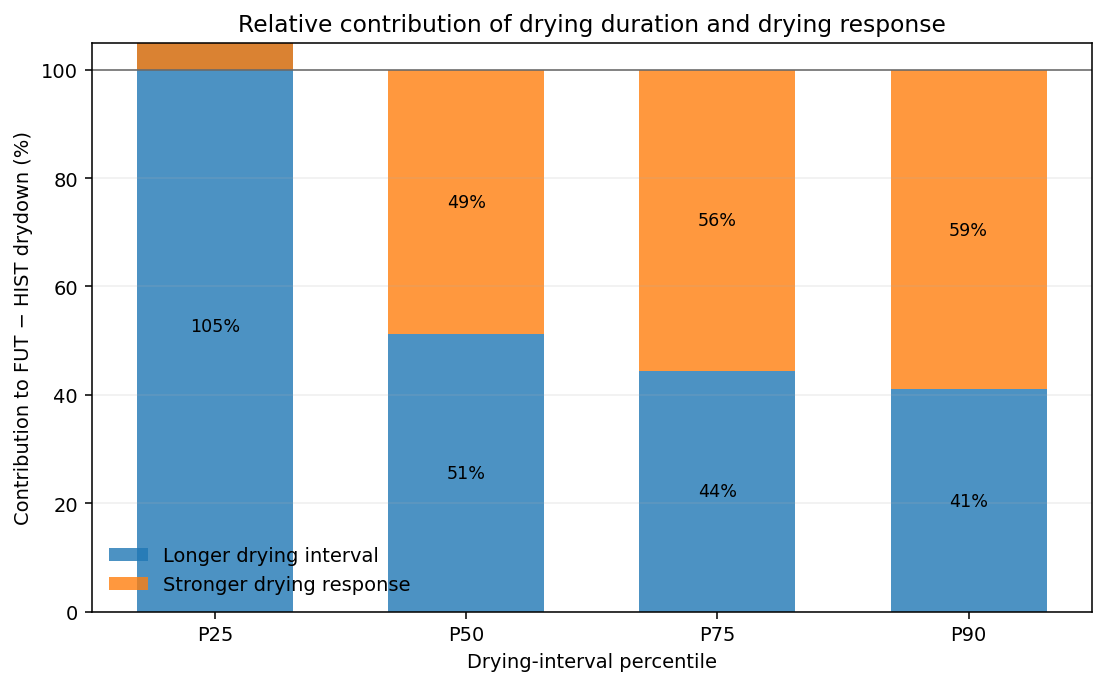

In [10]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=140)

x = np.arange(len(decomp))

dur = decomp["duration_percent"].values
resp = decomp["response_percent"].values

ax.bar(
    x, dur,
    width=0.62,
    label="Longer drying interval",
    alpha=0.8
)

ax.bar(
    x, resp,
    width=0.62,
    bottom=dur,
    label="Stronger drying response",
    alpha=0.8
)

for i, (d, r) in enumerate(zip(dur, resp)):
    if d > 8:
        ax.text(
            i, d/2,
            f"{d:.0f}%",
            ha="center",
            va="center",
            fontsize=9
        )

    if r > 8:
        ax.text(
            i, d + r/2,
            f"{r:.0f}%",
            ha="center",
            va="center",
            fontsize=9
        )

ax.axhline(100, color="0.4", lw=0.8)

ax.set_xticks(x)
ax.set_xticklabels(
    [f"P{int(p)}" for p in decomp["percentile"]]
)

ax.set_ylim(0, 105)

ax.set_ylabel("Contribution to FUT − HIST drydown (%)")
ax.set_xlabel("Drying-interval percentile")

ax.set_title(
    "Relative contribution of drying duration and drying response"
)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

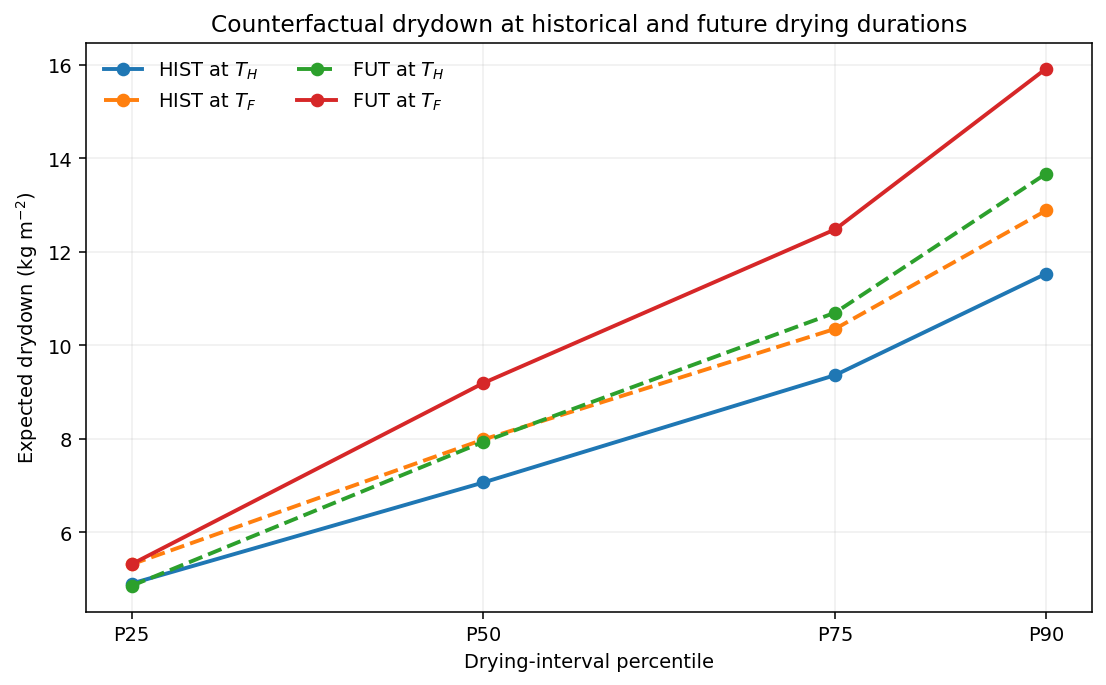

In [11]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=140)

p = decomp["percentile"].values

ax.plot(
    p,
    decomp["D_hist_at_Thist"],
    marker="o",
    lw=2,
    label=r"HIST at $T_H$"
)

ax.plot(
    p,
    decomp["D_hist_at_Tfuture"],
    marker="o",
    ls="--",
    lw=2,
    label=r"HIST at $T_F$"
)

ax.plot(
    p,
    decomp["D_future_at_Thist"],
    marker="o",
    ls="--",
    lw=2,
    label=r"FUT at $T_H$"
)

ax.plot(
    p,
    decomp["D_future_at_Tfuture"],
    marker="o",
    lw=2,
    label=r"FUT at $T_F$"
)

ax.set_xlabel("Drying-interval percentile")
ax.set_ylabel(r"Expected drydown (kg m$^{-2}$)")

ax.set_xticks(p)
ax.set_xticklabels([f"P{int(x)}" for x in p])

ax.set_title(
    "Counterfactual drydown at historical and future drying durations"
)

ax.legend(frameon=False, ncol=2)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [12]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
from shared.paths import load_paths

paths = load_paths()
ROOT = Path(paths.cp4_2d) / "CP4_box_JASMIN/SM_model_comparison25"

std = xr.open_dataset(ROOT / "SM_temporal_std_JAS12_onP25.nc")
wav = xr.open_dataset(ROOT / "SM_wavelet_persistence_JAS12_onP25.nc")

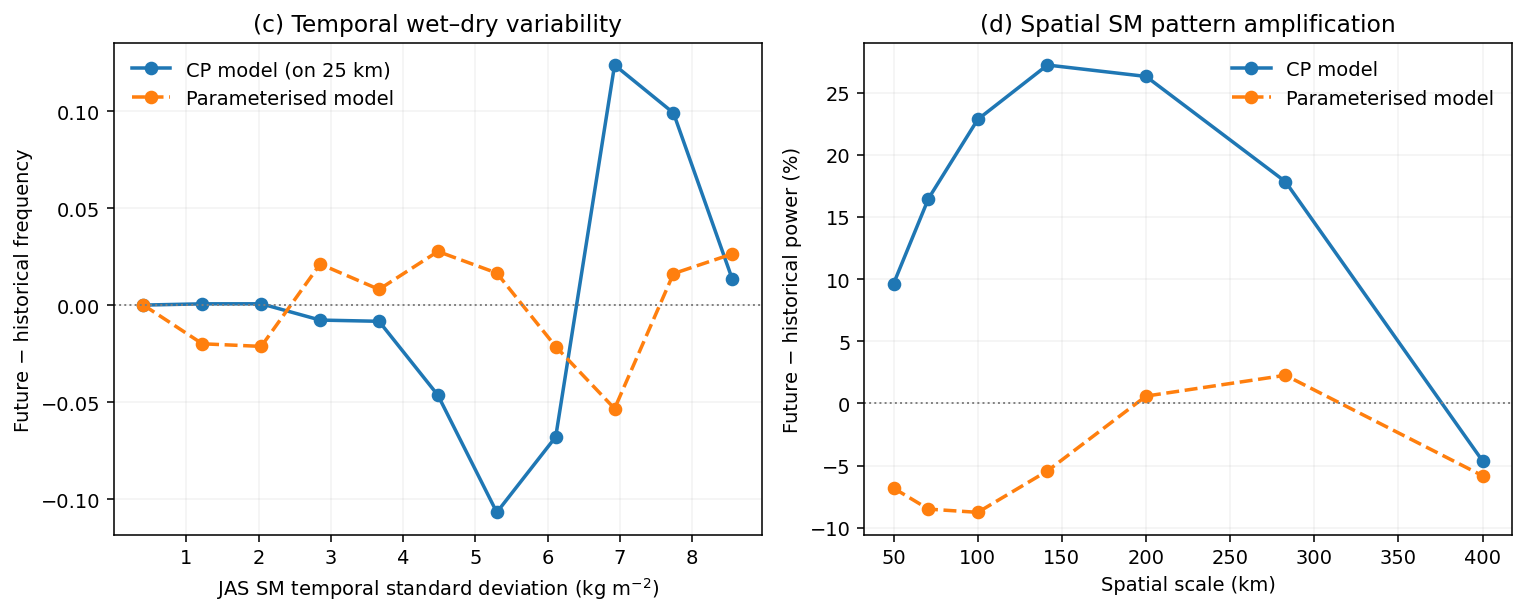

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), dpi=140)

ax = axes[0]

sh = std["SM_std_mean_years"]

cp_h = sh.sel(experiment="CP4hist").values.ravel()
cp_f = sh.sel(experiment="CP4fut").values.ravel()
p_h  = sh.sel(experiment="P25hist").values.ravel()
p_f  = sh.sel(experiment="P25fut").values.ravel()

allv = np.concatenate([cp_h, cp_f, p_h, p_f])
allv = allv[np.isfinite(allv)]

bins = np.linspace(0, np.nanpercentile(allv, 99.5), 12)
centres = 0.5 * (bins[:-1] + bins[1:])

def prob(v):
    v = v[np.isfinite(v)]
    n, _ = np.histogram(v, bins=bins)
    return n / n.sum()

ax.plot(centres, prob(cp_f)-prob(cp_h), marker="o", lw=1.8,
        label="CP model (on 25 km)")
ax.plot(centres, prob(p_f)-prob(p_h), marker="o", lw=1.8, ls="--",
        label="Parameterised model")

ax.axhline(0, color="0.5", lw=1, ls=":")
ax.set_xlabel(r"JAS SM temporal standard deviation (kg m$^{-2}$)")
ax.set_ylabel("Future − historical frequency")
ax.set_title("(c) Temporal wet–dry variability")
ax.legend(frameon=False)
ax.grid(alpha=0.15)

ax = axes[1]

p = wav["power_mean_years"]
scales = wav.scale.values

for model, ls, label in [
    ("CP4", "-", "CP model"),
    ("P25", "--", "Parameterised model"),
]:
    hist = p.sel(experiment=f"{model}hist").values
    fut  = p.sel(experiment=f"{model}fut").values

    change = 100 * (fut - hist) / hist

    ax.plot(scales, change, marker="o", lw=1.8, ls=ls, label=label)

ax.axhline(0, color="0.5", lw=1, ls=":")
ax.set_xlabel("Spatial scale (km)")
ax.set_ylabel("Future − historical power (%)")
ax.set_title("(d) Spatial SM pattern amplification")
ax.legend(frameon=False)
ax.grid(alpha=0.15)

plt.tight_layout()
plt.show()

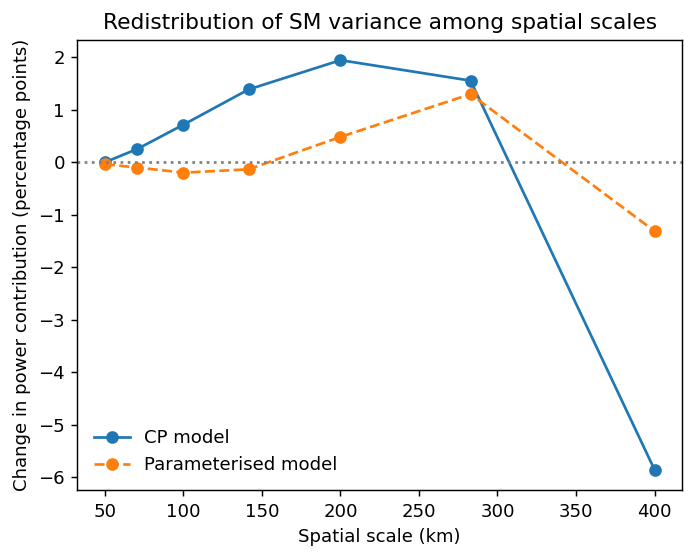

In [15]:
f = wav["power_fraction_mean_years"]

fig, ax = plt.subplots(figsize=(6, 4.5), dpi=130)

for model, ls, label in [
    ("CP4", "-", "CP model"),
    ("P25", "--", "Parameterised model"),
]:
    hist = f.sel(experiment=f"{model}hist")
    fut  = f.sel(experiment=f"{model}fut")

    ax.plot(
        wav.scale,
        100 * (fut - hist),
        marker="o",
        ls=ls,
        label=label
    )

ax.axhline(0, color="0.5", ls=":")
ax.set_xlabel("Spatial scale (km)")
ax.set_ylabel("Change in power contribution (percentage points)")
ax.set_title("Redistribution of SM variance among spatial scales")
ax.legend(frameon=False)
plt.show()

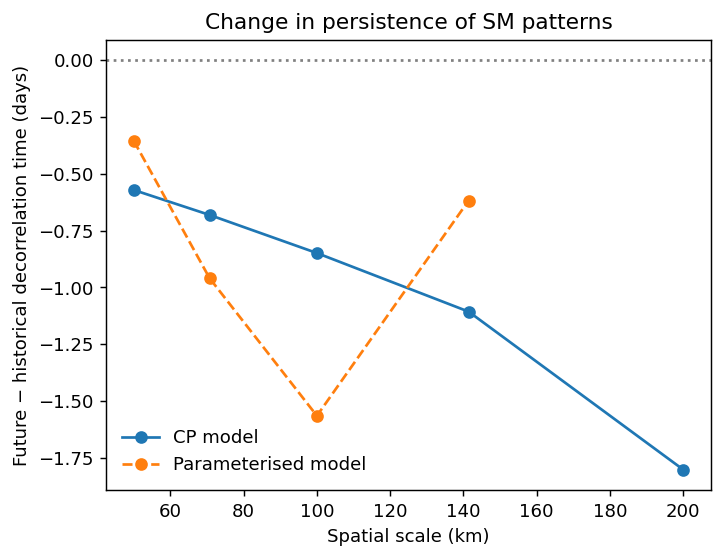

In [16]:
tau = wav["decorrelation_days_mean_years"]

fig, ax = plt.subplots(figsize=(6, 4.5), dpi=130)

for model, ls, label in [
    ("CP4", "-", "CP model"),
    ("P25", "--", "Parameterised model"),
]:
    hist = tau.sel(experiment=f"{model}hist")
    fut  = tau.sel(experiment=f"{model}fut")

    ax.plot(
        wav.scale,
        fut-hist,
        marker="o",
        ls=ls,
        label=label
    )

ax.axhline(0, color="0.5", ls=":")
ax.set_xlabel("Spatial scale (km)")
ax.set_ylabel("Future − historical decorrelation time (days)")
ax.set_title("Change in persistence of SM patterns")
ax.legend(frameon=False)
plt.show()